# Growth from the expansion: an H(z) spline instead of free f, D and α
`growth_from_h` = `bao_template_no_rs` with the 23 numbers f(z_i), α_∥(z_i), α_⊥(z_i), D(z_i)/D(z_N) replaced by 9: $s(z)=\ln[H r_d/(H r_d)_{\rm fid}]$ on 8 nodes (z = 0, 0.15 and the six data redshifts; cubic spline in ln(1+z)) and $\mu=\ln[\Omega_m(H_0r_d)^2/{\rm fid}]$. Then $\alpha_\parallel=D_H/r_d$ over its fiducial, $\alpha_\perp$ from $D_M/r_d=\int_0^z D_H/r_d\,dz$, and $D$, $f$ from

$$D''+\Big(2+\frac{d\ln H}{d\ln a}\Big)D'-\frac32\Omega_m(a)D=0,\qquad \Omega_m(a)=\frac{\Omega_mH_0^2a^{-3}}{H^2},$$

matter domination at a = 10⁻³; above z_N = 1.49 the dark-energy density $H^2-\Omega_mH_0^2(1+z)^3$ keeps its value at z_N.

Valid for: GR, scale-independent growth (no massive-neutrino or modified-gravity scale dependence), smooth dark energy, a flat universe, and a dark-energy density that does not grow above z = 1.49. Same P(k) template, EFT priors, data and sampler as the baseline. DESI-alone priors: BBN ω_b, n_s ~ N(0.9649, 0.042).

In [1]:
import sys; sys.path.insert(0, '../mi')
import plots as P
P.OPTS = ('bao_template_no_rs', 'growth_from_h')

## Does it contain ΛCDM, w0waCDM and EDE?
`checks.py growth`: at the map of 300 direct-fit draws of each model, the spline + growth equation against the cosmology's own f, α, D; and the shift of the posterior mean implied by the likelihood difference.

In [2]:
P.growth_validity()

cosmology          f  alpha_par  alpha_per   D ratio  Delta chi2 sd  max |implied shift|
LCDM         7.8e-04    5.7e-16    4.4e-05   3.6e-04           0.07                 0.01
w0waCDM      4.2e-03    6.6e-16    1.6e-03   1.1e-03           0.35                 0.06
EDE          7.8e-04    6.6e-16    4.1e-05   3.6e-04           0.07                 0.01


## The chains

In [3]:
P.chain_table()

template            params  chains x draws max R-hat  min ESS median ESS divergent  seeds


bao_template_no_rs      58      96 x 1000      1.019     6176      21666    0.0091  chain_seed1.npz, chain_seed2.npz, chain_seed3.npz
growth_from_h           44      32 x 830       1.005     6012       7532    0.0020  chain_seed1.npz


## The data's test of the growth equation
χ² at the maximum of the posterior, `growth_from_h` against the baseline, for 14 fewer parameters. `checks.py bestfit`: L-BFGS-B from 9 starting points (the best fit the chains start from, the chain mean, the chain's best draw, 6 random draws), each restarted until it stops improving. The posterior has shallow local maxima about 1σ apart, so the end points differ (χ² by up to 18 for the baseline, 9 for `growth_from_h`); the highest of each is reached from two starts. Between those, Δχ² = 23 for 14 parameters (p = 0.06): the free growth is not required. The best fit that `run.py chain` starts from is one such local maximum, not the highest.

In [4]:
P.bestfit_table()

template            params        chain start      highest found   chi2 / ln posterior;  chi2 of every end point


bao_template_no_rs      58    287.31 / -145.42    272.73 / -139.76   287.3 272.7 285.2 270.9 289.3 280.4 272.9 280.4 278.3
growth_from_h           44    302.00 / -152.81    296.22 / -151.18   302.0 296.3 296.2 297.6 298.8 300.1 304.7 297.9 304.2


## f, α and D at the data redshifts: derived from H(z) against free
Filled: chain mean and 68%. Open: best fit. Grey: fiducial ΛCDM. f is degenerate with the amplitude and the biases, so its marginal is set by the prior volume in both templates: chain means above the best fits. The projections below evaluate the likelihood on each model's own f(z) and do not use these marginals.

f     sd(derived) / sd(free) at z = [0.3  0.51 0.71 0.92 1.32 1.49]: [0.17 0.23 0.27 0.3  0.3  0.31];  (derived - free) / sd(free): [-0.88 -1.4  -0.84 -0.67 -0.04 -0.39]
apar  sd(derived) / sd(free) at z = [0.3  0.51 0.71 0.92 1.32 1.49]: [0.84 0.86 0.75 0.82 0.82 0.91];  (derived - free) / sd(free): [-0.86  0.44 -0.29  0.09  0.48  1.02]
aper  sd(derived) / sd(free) at z = [0.3  0.51 0.71 0.92 1.32 1.49]: [0.71 0.61 0.45 0.44 0.24 0.19];  (derived - free) / sd(free): [ 1.27 -1.02  1.98 -0.79 -1.08 -0.05]
D     sd(derived) / sd(free) at z = [0.3  0.51 0.71 0.92 1.32]: [0.32 0.24 0.15 0.11 0.02];  (derived - free) / sd(free): [ 1.54  1.08  0.57  0.42 -0.17]
ln Omega_m (H0 r_d)^2 / fiducial: best fit +0.15, chain +0.68 +- 0.25


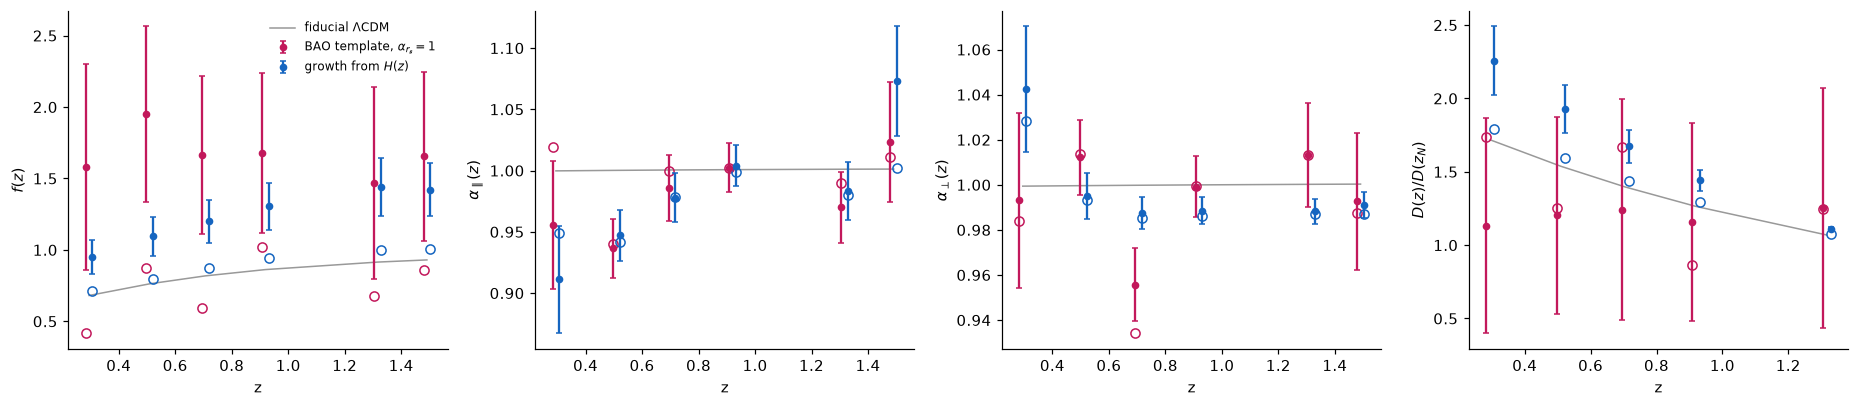

In [5]:
P.growth_from_h();

## Cosmology through the reconstruction
Both templates projected, against the direct fits.
### ΛCDM

LCDM: direct fit; MI: shift [direct sigma] / width ratio
   omega_cdm   direct 0.1183 +- 0.0057   bao_template_no_rs 0.1183 +- 0.0058 (+0.01 / 1.02)   growth_from_h 0.1179 +- 0.0058 (-0.06 / 1.02)
   omega_b     direct 0.0221 +- 0.0005   bao_template_no_rs 0.0221 +- 0.0005 (+0.02 / 1.01)   growth_from_h 0.0221 +- 0.0005 (+0.01 / 1.00)
   n_s         direct 0.9870 +- 0.0296   bao_template_no_rs 0.9835 +- 0.0292 (-0.12 / 0.99)   growth_from_h 0.9868 +- 0.0293 (-0.00 / 0.99)
   lnAs        direct 3.0530 +- 0.0983   bao_template_no_rs 3.0465 +- 0.0987 (-0.07 / 1.00)   growth_from_h 3.0473 +- 0.1012 (-0.06 / 1.03)
   h           direct 0.6856 +- 0.0074   bao_template_no_rs 0.6857 +- 0.0074 (+0.01 / 1.00)   growth_from_h 0.6860 +- 0.0074 (+0.06 / 1.01)


Removed no burn in
Removed no burn in
Removed no burn in


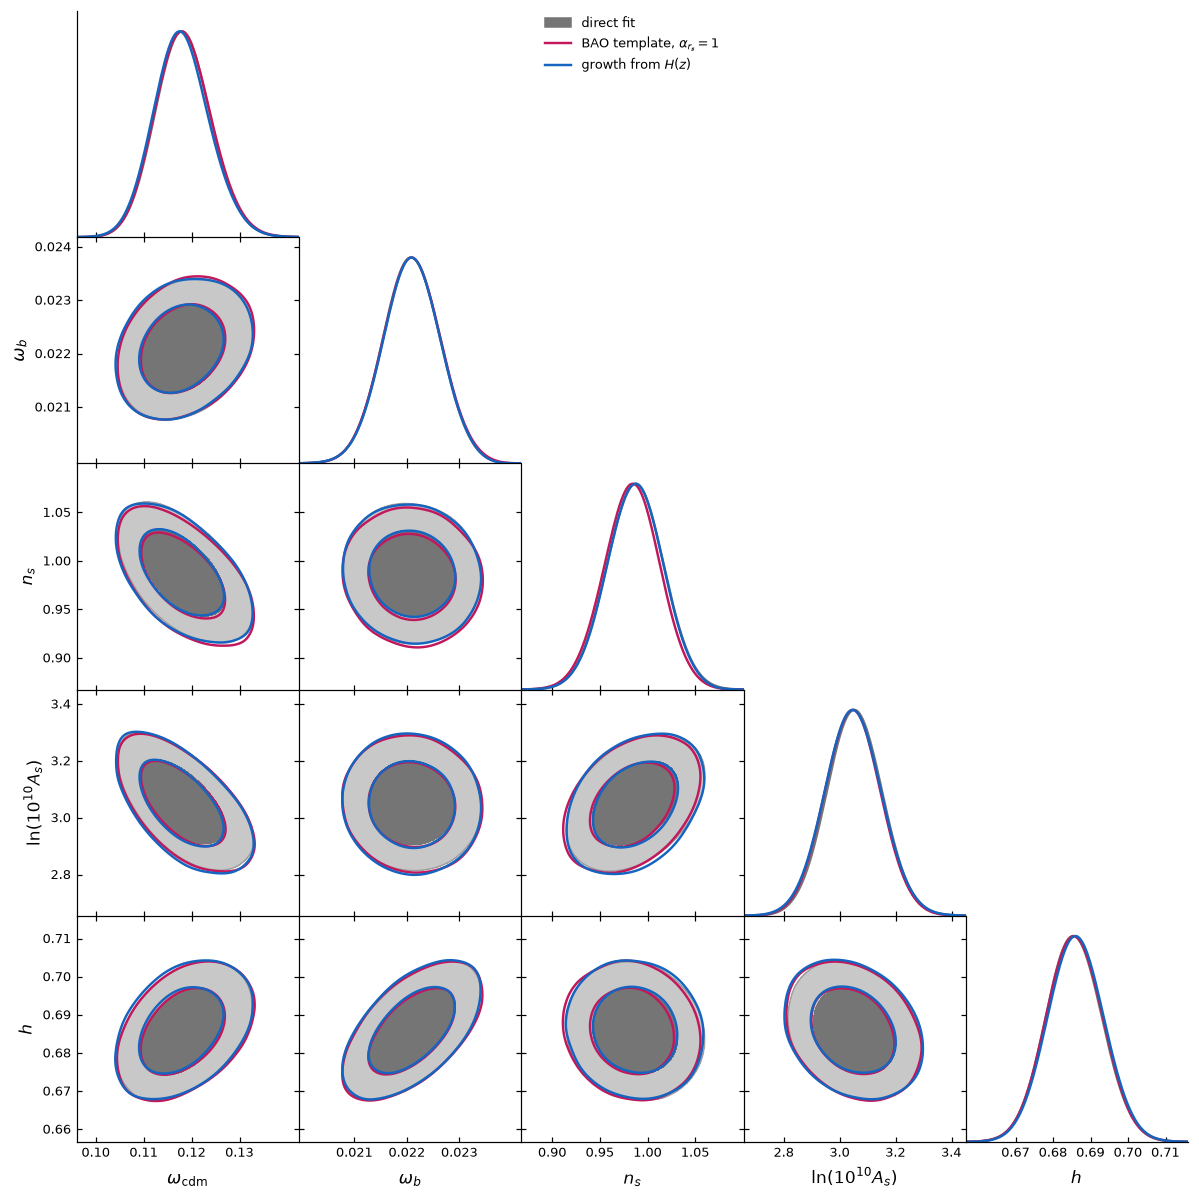

In [6]:
P.direct_vs_mi('lcdm', opts=P.OPTS);

LCDM + theta_s: direct fit \times\ \theta_s prior (3024 effective of 64000 draws); MI: shift [direct sigma] / width ratio
   omega_cdm   direct 0.1162 +- 0.0014   bao_template_no_rs 0.1162 +- 0.0014 (-0.05 / 0.99)   growth_from_h 0.1161 +- 0.0014 (-0.12 / 1.01)
   omega_b     direct 0.0221 +- 0.0005   bao_template_no_rs 0.0221 +- 0.0005 (+0.01 / 1.02)   growth_from_h 0.0221 +- 0.0005 (+0.05 / 1.04)
   n_s         direct 0.9930 +- 0.0252   bao_template_no_rs 0.9891 +- 0.0250 (-0.15 / 0.99)   growth_from_h 0.9915 +- 0.0252 (-0.06 / 1.00)
   lnAs        direct 3.0721 +- 0.0778   bao_template_no_rs 3.0664 +- 0.0783 (-0.07 / 1.01)   growth_from_h 3.0646 +- 0.0805 (-0.10 / 1.04)
   h           direct 0.6841 +- 0.0062   bao_template_no_rs 0.6844 +- 0.0062 (+0.05 / 0.99)   growth_from_h 0.6850 +- 0.0063 (+0.14 / 1.01)
Removed no burn in
Removed no burn in
Removed no burn in


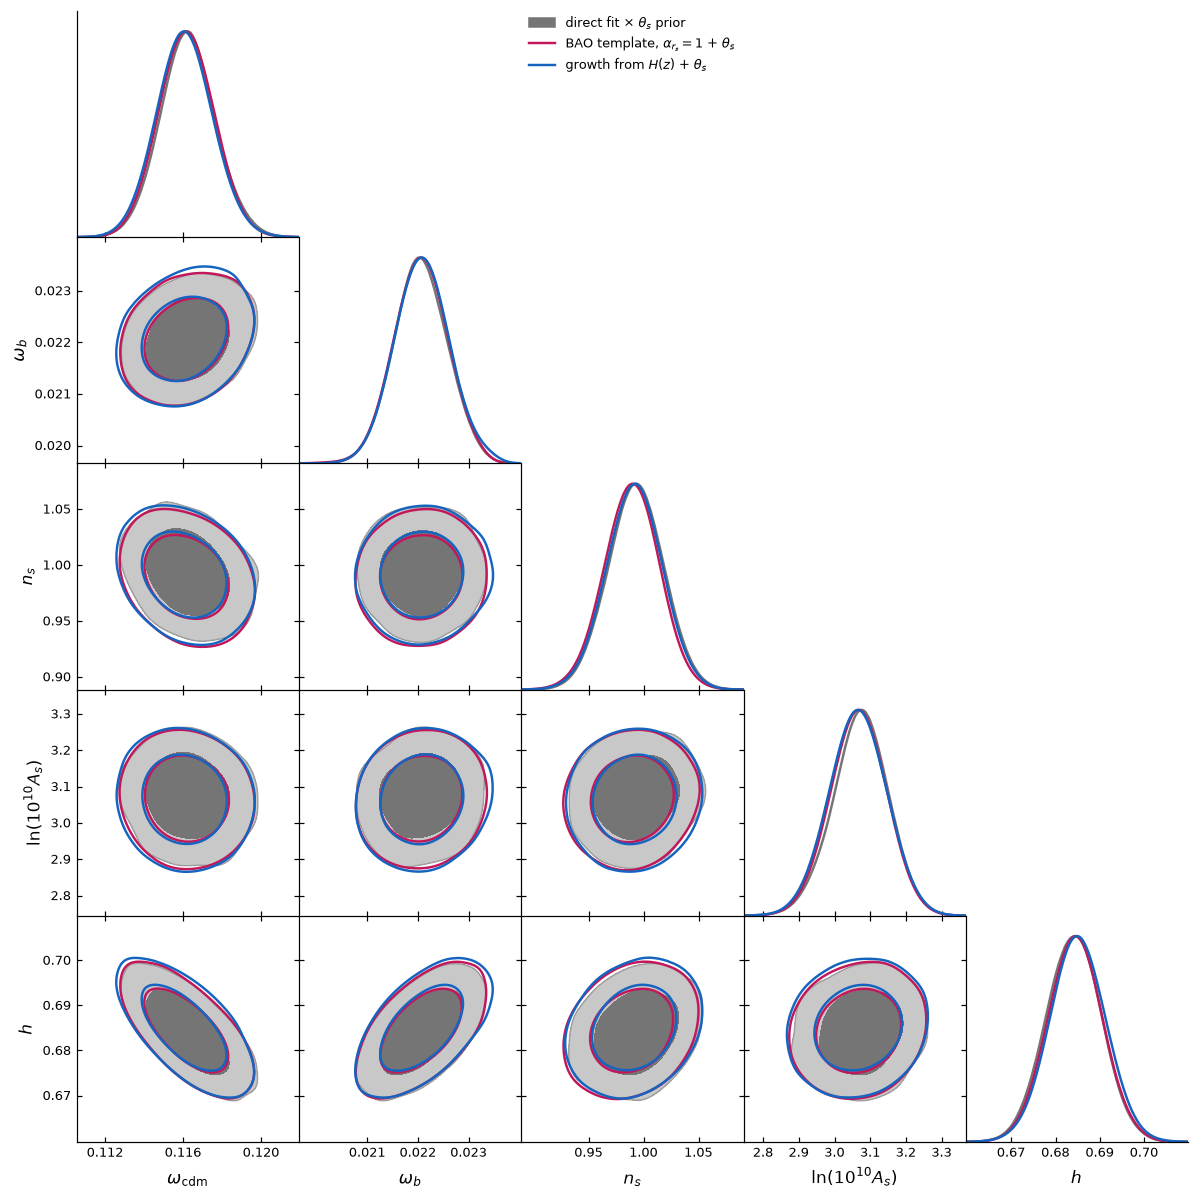

In [7]:
P.direct_vs_mi('lcdm', theta_s=True, opts=P.OPTS);

### w0waCDM

w0waCDM: direct fit, EFT priors in sound-horizon units; MI: shift [direct sigma] / width ratio
   omega_cdm   direct 0.1212 +- 0.0066   bao_template_no_rs 0.1215 +- 0.0066 (+0.04 / 1.00)   growth_from_h 0.1214 +- 0.0067 (+0.03 / 1.02)
   omega_b     direct 0.0221 +- 0.0005   bao_template_no_rs 0.0221 +- 0.0005 (+0.02 / 1.01)   growth_from_h 0.0221 +- 0.0005 (+0.02 / 1.00)
   n_s         direct 0.9751 +- 0.0307   bao_template_no_rs 0.9720 +- 0.0307 (-0.10 / 1.00)   growth_from_h 0.9739 +- 0.0311 (-0.04 / 1.01)
   lnAs        direct 2.9625 +- 0.1248   bao_template_no_rs 2.9553 +- 0.1240 (-0.06 / 0.99)   growth_from_h 2.9545 +- 0.1277 (-0.06 / 1.02)
   h           direct 0.6622 +- 0.0316   bao_template_no_rs 0.6604 +- 0.0309 (-0.06 / 0.98)   growth_from_h 0.6639 +- 0.0312 (+0.05 / 0.99)
   w0          direct -0.6181 +- 0.3162   bao_template_no_rs -0.6005 +- 0.3090 (+0.06 / 0.98)   growth_from_h -0.6255 +- 0.3156 (-0.02 / 1.00)
   wa          direct -1.4113 +- 0.9907   bao_template_no_rs -

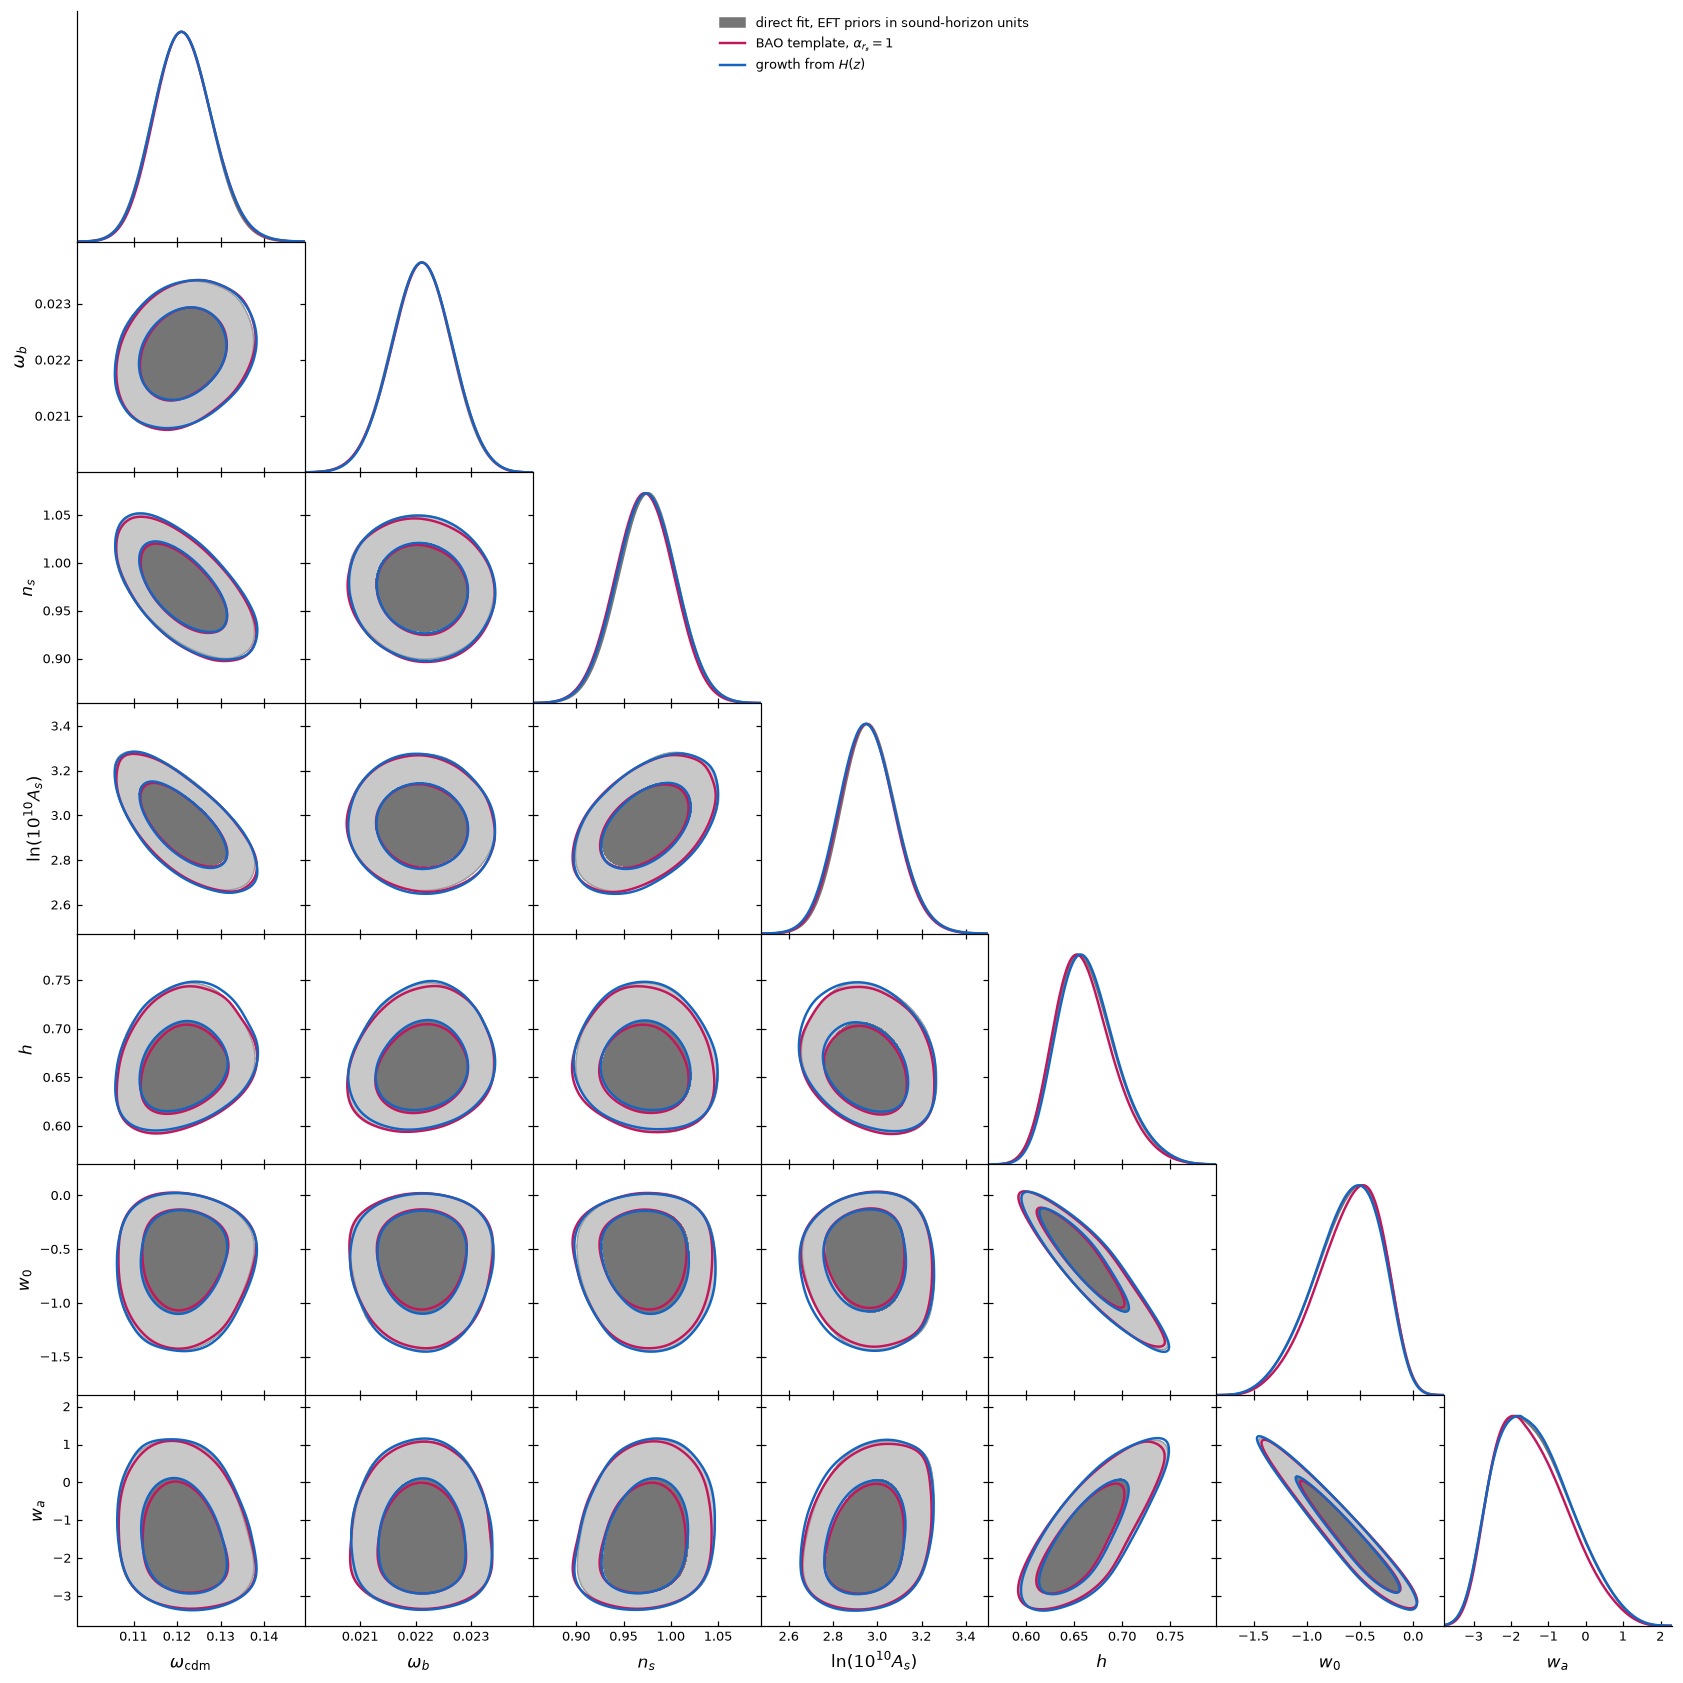

In [8]:
P.direct_vs_mi('w0wa', rd=True, opts=P.OPTS);

w0waCDM + theta_s: direct fit, EFT priors in sound-horizon units \times\ \theta_s prior (2383 effective of 51200 draws); MI: shift [direct sigma] / width ratio
   omega_cdm   direct 0.1203 +- 0.0028   bao_template_no_rs 0.1203 +- 0.0027 (+0.00 / 0.95)   growth_from_h 0.1201 +- 0.0027 (-0.06 / 0.97)
   omega_b     direct 0.0221 +- 0.0005   bao_template_no_rs 0.0221 +- 0.0005 (-0.01 / 1.00)   growth_from_h 0.0221 +- 0.0005 (-0.03 / 1.01)
   n_s         direct 0.9776 +- 0.0258   bao_template_no_rs 0.9752 +- 0.0262 (-0.09 / 1.02)   growth_from_h 0.9767 +- 0.0264 (-0.03 / 1.03)
   lnAs        direct 2.9653 +- 0.1066   bao_template_no_rs 2.9646 +- 0.1039 (-0.01 / 0.97)   growth_from_h 2.9630 +- 0.1070 (-0.02 / 1.00)
   h           direct 0.6603 +- 0.0287   bao_template_no_rs 0.6589 +- 0.0275 (-0.05 / 0.96)   growth_from_h 0.6622 +- 0.0279 (+0.07 / 0.97)
   w0          direct -0.6014 +- 0.3006   bao_template_no_rs -0.5957 +- 0.2841 (+0.02 / 0.95)   growth_from_h -0.6210 +- 0.2890 (-0.07 / 0.9

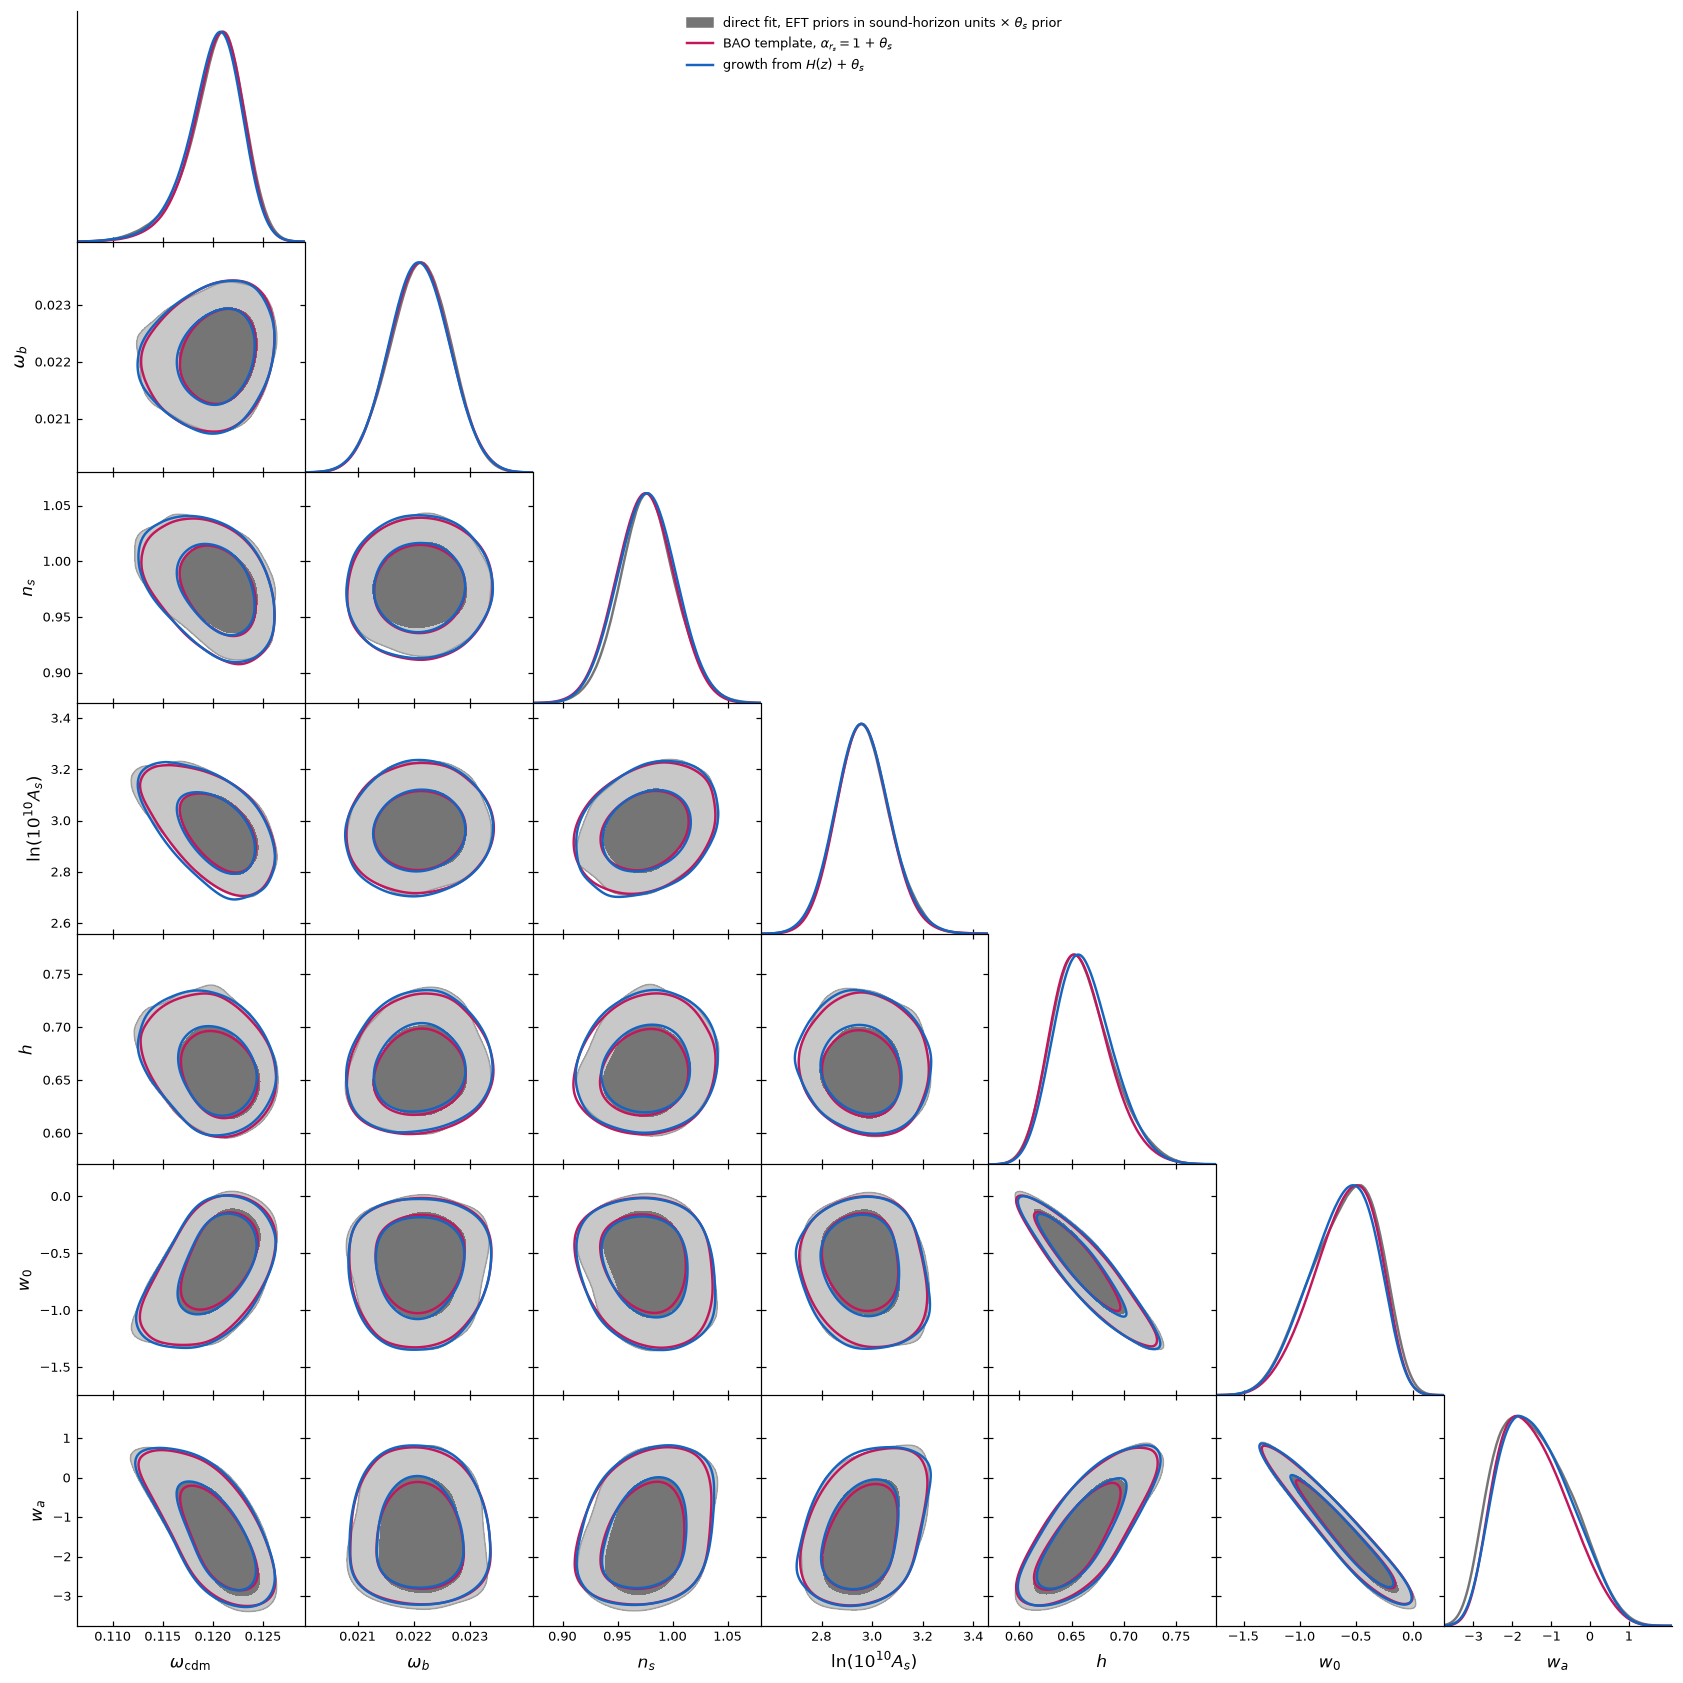

In [9]:
P.direct_vs_mi('w0wa', rd=True, theta_s=True, opts=P.OPTS);